# Lecture 2: from fitting a distribution to an autoencoder

65-minute slide-led lecture companion. This offline package bundles a fixed binary MNIST subset and existing trained AE weights. It **replays** these models and performs an actual copied-checkpoint update; it does not claim to retrain the recorded checkpoints.

Data: official train images0–255 and test images0–1999, thresholded once at raw/255>0.5. Held image is official test index90. No test image is used in an update or fitted-code density. Logs are natural; losses sum pixels then average images.

Run top-to-bottom in the lecture folder. The environment needs Torch, NumPy and Matplotlib; the supplied machine has `/Users/nipun/git/clip-lab/.venv/bin/python`. No network or download is used.

In [1]:
from pathlib import Path
import sys, json, math, copy
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.nn import functional as F
from IPython.display import display, Image, SVG
ROOT = Path.cwd()
if not (ROOT / "data/mnist-snapshot.npz").exists():
    raise RuntimeError("Run this notebook with its lecture folder as the working directory.")
sys.path.insert(0, str(ROOT / "notebooks"))
import lab
lab.ROOT = ROOT
torch.set_num_threads(2)
torch.manual_seed(667)
d = lab.data()
x_train, x_test = d["train"], d["test"]
held3 = x_test[90:91]
fixtures = json.loads((ROOT / "data/fixtures.json").read_text())
print("Torch", torch.__version__)
print("Snapshot:", tuple(x_train.shape), tuple(x_test.shape))
print("Binary observations:", torch.unique(x_test).tolist())
print("Held image: official test index90, label", int(d["test_labels"][90]))
assert torch.all((x_test == 0) | (x_test == 1))
assert int(d["test_labels"][90]) == 3


Torch 2.13.0
Snapshot: (256, 28, 28) (2000, 28, 28)
Binary observations: [0.0, 1.0]
Held image: official test index90, label 3


## 1. Observe the same handwritten 3
Before looking at a reconstruction, describe what the decoder must preserve.

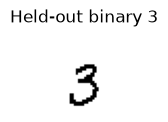

Ink pixels: 100


In [2]:
def show_grid(images, columns=10, title=""):
    images = np.asarray(images).reshape(-1,28,28)
    rows = int(np.ceil(len(images)/columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns*1.2,rows*1.2), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, img in zip(axes.flat, images): ax.imshow(img,cmap="gray_r",vmin=0,vmax=1)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

show_grid(held3, 1, "Held-out binary 3")
print("Ink pixels:", int(held3.sum()))

## 2. Fit, then sample a small distribution
The component labels are unobserved. The following small EM implementation fits a two-Gaussian mixture to the same twelve points used in the slides. The component choice is the latent variable.

One Gaussian: mean/std -0.03333333333333325 2.361614325460917
Mixture weights, means, stds: [0.5 0.5] [-2.33333333  2.26666667] [0.53437398 0.53748385]


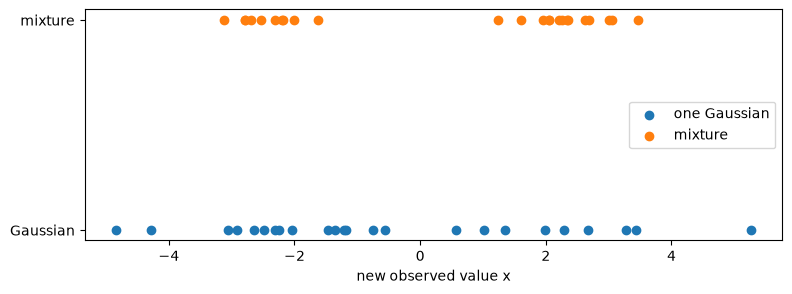

In [3]:
x=np.array([-3.2,-2.8,-2.4,-2.1,-1.8,-1.7,1.5,1.8,2.1,2.4,2.7,3.1])
mean, std=x.mean(),x.std()
means=np.array([-2.,2.]);stds=np.ones(2);weights=np.ones(2)/2
for step in range(40):
    density=np.exp(-.5*((x[:,None]-means)/stds)**2)/stds/np.sqrt(2*np.pi)*weights
    responsibility=density/density.sum(1,keepdims=True)
    count=responsibility.sum(0)
    weights=count/len(x)
    means=(responsibility*x[:,None]).sum(0)/count
    stds=np.sqrt((responsibility*(x[:,None]-means)**2).sum(0)/count)
print("One Gaussian: mean/std",mean,std)
print("Mixture weights, means, stds:",weights,means,stds)
assert np.allclose(means,fixtures["toy"]["means"])
rng=np.random.default_rng(674)
single=rng.normal(mean,std,24)
component=rng.choice(2,24,p=weights)
mixture=rng.normal(means[component],stds[component])
plt.figure(figsize=(9,3));plt.scatter(single,np.zeros(24),label="one Gaussian")
plt.scatter(mixture,np.ones(24),label="mixture");plt.yticks([0,1],["Gaussian","mixture"])
plt.xlabel("new observed value x");plt.legend();plt.show()

**Predict:** if we double the number of generated points, have we fitted a new model?

**Answer:** no. The fitted parameters stay fixed. Only the sampling experiment changes.

## 3. Replay the AE and separate weights from activations
The encoder computes a deterministic code; it does not define an approximate posterior distribution. The decoder returns logits. The network class is local in `notebooks/lab.py`.

AutoEncoder(
  (encoder): Encoder(
    (body): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=784, out_features=512, bias=True)
      (2): ReLU()
      (3): Linear(in_features=512, out_features=256, bias=True)
      (4): ReLU()
    )
    (mu): Linear(in_features=256, out_features=2, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=2, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=512, bias=True)
      (3): ReLU()
      (4): Linear(in_features=512, out_features=784, bias=True)
    )
  )
)
held3 code: [[0.29268354 1.2160922 ]]


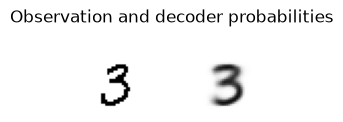

In [4]:
ae2,ae16=lab.model("ae2"),lab.model("ae16")
print(ae2)
with torch.no_grad():
    z=ae2.encoder(held3)[0]
    probability=ae2.decoder(z).sigmoid()
print("held3 code:",z.numpy())
show_grid(torch.cat([held3.flatten(1),probability]),2,"Observation and decoder probabilities")

## 4. A loss contribution and one actual training step
Use stable logits-based BCE. Sum the event dimensions (pixels); average images. Neither reduction is an arbitrary formatting choice.

In [5]:
observed=torch.tensor([[1.,0.,1.,0.]],dtype=torch.float64)
probability=torch.tensor([[.8,.1,.6,.3]],dtype=torch.float64)
contributions=-(observed*probability.log()+(1-observed)*(1-probability).log())
from_logits=F.binary_cross_entropy_with_logits(torch.logit(probability),observed,reduction="none")
print("Pixel contributions:",contributions.tolist())
print("Sum per image:",contributions.sum(1).tolist())
assert torch.allclose(contributions,from_logits,atol=1e-12)

# Copy the model: the bundled trained checkpoint is never overwritten.
model=copy.deepcopy(ae2).double()
xb=x_train[:8].double()
logits,mu,lv,_=model(xb)
per_image=F.binary_cross_entropy_with_logits(logits,xb.flatten(1),reduction="none").sum(1)
loss=per_image.mean()
model.zero_grad(set_to_none=True);loss.backward()
eta=1e-4
before={name:p.detach().clone() for name,p in model.named_parameters()}
with torch.no_grad():
    for parameter in model.parameters(): parameter -= eta*parameter.grad
    updated=F.binary_cross_entropy_with_logits(model(xb)[0],xb.flatten(1),reduction="none").sum(1).mean()
changes={name:float((parameter.detach()-before[name]).norm()) for name,parameter in model.named_parameters()}
print("Before/after nats per image:",float(loss.detach()),float(updated))
print("Encoder changed:",any(v>0 for name,v in changes.items() if name.startswith("encoder")))
print("Decoder changed:",any(v>0 for name,v in changes.items() if name.startswith("decoder")))
assert abs(float(updated)-fixtures["ae_step"]["after_same_noise"])<1e-8

Pixel contributions: [[0.2231435513142097, 0.10536051565782628, 0.5108256237659907, 0.35667494393873245]]
Sum per image: [1.1960046346767592]
Before/after nats per image: 121.43813710927049 121.08715497375138
Encoder changed: True
Decoder changed: True


## 5. Held-out reconstruction and bottleneck evidence
These are reconstructions, not new samples. Evaluate identical images and reductions for both dimensions.

ae2 test reconstruction nats/image: 127.61724853515625
ae16 test reconstruction nats/image: 44.62532424926758


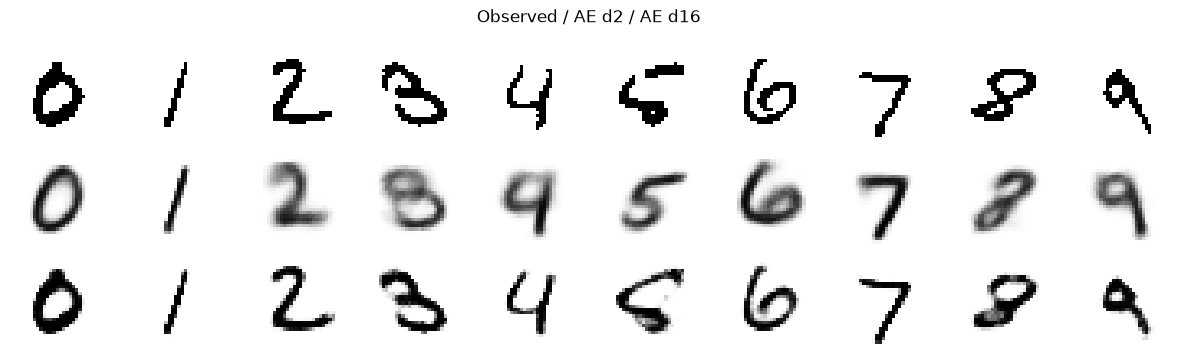

In [6]:
ids=torch.tensor([int(torch.where(d["test_labels"]==i)[0][0]) for i in range(10)])
with torch.no_grad():
    rows=[x_test[ids].flatten(1)]
    for name,model in [("ae2",ae2),("ae16",ae16)]:
        logits,mu,lv,_=model(x_test)
        loss=F.binary_cross_entropy_with_logits(logits,x_test.flatten(1),reduction="none").sum(1).mean()
        print(name,"test reconstruction nats/image:",float(loss))
        rows.append(logits[ids].sigmoid())
show_grid(torch.cat(rows),10,"Observed / AE d2 / AE d16")

## 6. Reconstruct, interpolate and sample are different experiments
Use exactly the same decoder. The code-cloud and prior overlay must keep the same axes. A standard-normal prior was not part of AE training.

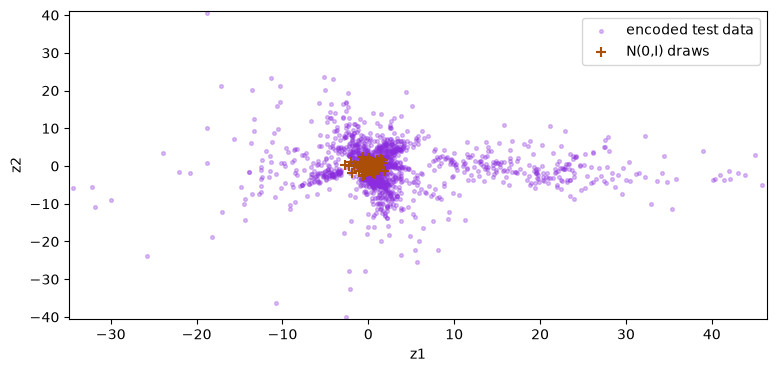

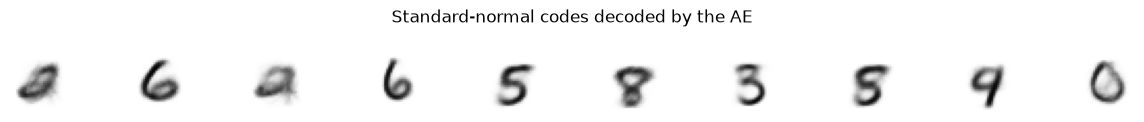

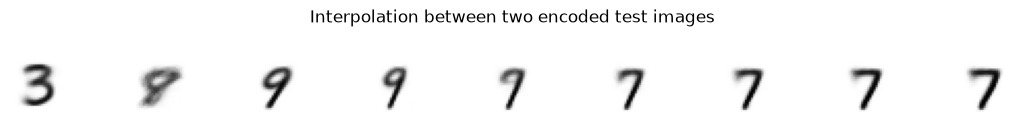

In [7]:
with torch.no_grad():
    codes=ae2.encoder(x_test)[0]
    prior=torch.randn(80,2,generator=torch.Generator().manual_seed(667))
    decoded=ae2.decoder(prior[:10]).sigmoid()
limits=fixtures["code_axes"]
fig,ax=plt.subplots(figsize=(9,4))
ax.scatter(codes[:,0],codes[:,1],s=7,alpha=.3,label="encoded test data",c="#8B2CDE")
ax.scatter(prior[:,0],prior[:,1],marker="+",s=50,label="N(0,I) draws",c="#AA4E08")
ax.set(xlim=limits[0],ylim=limits[1],xlabel="z1",ylabel="z2");ax.legend();plt.show()
show_grid(decoded,10,"Standard-normal codes decoded by the AE")
with torch.no_grad():
    i7=int(torch.where(d["test_labels"]==7)[0][0])
    t=torch.linspace(0,1,9).unsqueeze(1)
    line=(1-t)*codes[90]+t*codes[i7]
    interpolation=ae2.decoder(line).sigmoid()
show_grid(interpolation,9,"Interpolation between two encoded test images")

## 7. A separate density model for the codes
Fit this Gaussian only on training-image codes. It is a legitimate additional model, but a single Gaussian can miss multimodal code geometry. This tiny 256-image fit is a demonstration, not a quality benchmark.

Fitted training-code mean: [1.788147211074829, -0.45904675126075745]


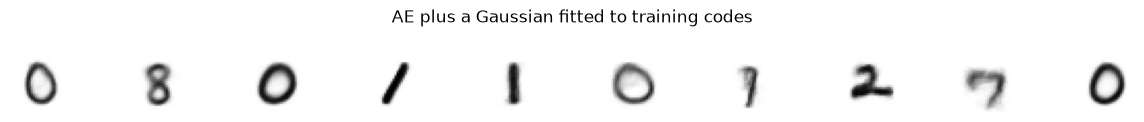

In [8]:
with torch.no_grad():
    training_codes=ae2.encoder(x_train)[0]
    mean=training_codes.mean(0)
    covariance=torch.cov(training_codes.T)+1e-4*torch.eye(2)
    epsilon=torch.randn(10,2,generator=torch.Generator().manual_seed(670))
    new_codes=mean+epsilon@torch.linalg.cholesky(covariance).T
    fitted_samples=ae2.decoder(new_codes).sigmoid()
print("Fitted training-code mean:",mean.tolist())
show_grid(fitted_samples,10,"AE plus a Gaussian fitted to training codes")

## 8. Optional small fresh training run
This trains a new model on the bundled 256-image subset. It cannot reproduce the full recorded model quality. Set the switch to True deliberately; results remain in memory.

In [9]:
RUN_SMALL_TRAINING=False
if RUN_SMALL_TRAINING:
    torch.manual_seed(667)
    fresh=lab.AutoEncoder(2,False)
    optimizer=torch.optim.Adam(fresh.parameters(),lr=1e-3)
    for epoch in range(10):
        logits,mu,lv,_=fresh(x_train)
        objective=F.binary_cross_entropy_with_logits(logits,x_train.flatten(1),reduction="none").sum(1).mean()
        optimizer.zero_grad(set_to_none=True);objective.backward();optimizer.step()
    print("Final tiny-subset training loss:",float(objective.detach()))
else:
    print("Optional fresh training skipped; replay and actual inspected update above have run.")

Optional fresh training skipped; replay and actual inspected update above have run.


## Exit questions and answers
1. What distribution supplied the new AE codes? **We chose one; reconstruction did not specify it.**
2. Does interpolation prove quality under a standard-normal prior? **No. It follows a selected path between encoded examples.**
3. What changes in the VAE? **An explicit prior and likelihood create an inference problem; an encoder amortises a variational approximation.**

Provenance and checkpoint hashes: `data/provenance.json`. Figures and their hashes: `data/figure-manifest.json`. Original checkpoint training histories: `data/original-training.json`.